# Grand Canyon at Phantom Ranch, March 4–20

What the weather and the Colorado River's flow did at Phantom Ranch from March 4 to March 20 in each year from 2015 to 2026, using the same NOAA and USGS readers that build max-float's conditions.

- **Weather on the canyon floor:** NOAA GHCN-Daily station USC00026471, PHANTOM RCH, at 771 m. Daily high and low in °F, and precipitation and snowfall in inches.
- **Snow on the rim:** USC00023582, GRAND CANYON VISITOR CTR, 5 km away on the South Rim at 2,159 m. It has no March readings in 2021.
- **Wind:** USW00003195, GRAND CANYON NP AP, 19 km away on the South Rim at 1,993 m. Phantom Ranch has no wind instrument, and the closest station with one is this airport, so its wind is the rim's, not the river's. Average daily wind and the day's fastest 5-second gust, in mph.
- **Flow:** USGS gauge 09402500, Colorado River near Grand Canyon, AZ, less than a kilometre from Phantom Ranch. Mean daily discharge in cfs.

Glen Canyon Dam sets this flow, so it changes with release schedules more than with weather. Within a day it also rises and falls with power demand, which a daily mean hides. USGS marks its most recent data provisional, so 2026 may still be revised.

## What it shows

- **A typical day** in this window had about 11,700 cfs, a high of 72°F and a low of 46°F.
- **Nights rarely froze.** Only 2 of 202 nights reached 32°F, both in 2022.
- **About one day in five had precipitation**, and amounts were small. The wettest window was 2020, with 1.07 inches over 6 days.
- **No snow fell at Phantom Ranch** on any of these days. On the South Rim, snow fell in 9 of the 11 years with readings, most in 2025, with 16.3 inches.
- **Wind on the rim was usually light**, with a median day averaging 5.8 mph, but gusts reached 40 mph or more on 16 of 198 days. The strongest was 59 mph, on March 5, 2022.
- **Flows have been lower lately.** The window averaged 13,070 cfs from 2015 to 2020 and 10,100 cfs from 2021 to 2026.
- **2026 was the outlier.** It had the lowest and steadiest flow, 8,370 to 8,860 cfs, and the hottest weather, averaging 83°F with highs of 96 to 99°F on March 18 to 20, when the median high is about 76°F. It was also the driest and calmest, with 0.10 inches of rain, no rim snow, and the lowest mean wind, 5.0 mph.
- **2021 changed mid-window.** Flow fell from about 12,000 cfs to about 4,500 cfs over March 16 and 17. A step that sharp comes from dam releases, not weather.

In [1]:
import datetime

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter, MultipleLocator

from max_float import config
from max_float.ingest import noaa, usgs

STATION = "USC00026471"  # PHANTOM RCH, on the canyon floor
RIM = "USC00023582"  # GRAND CANYON VISITOR CTR, on the South Rim
WIND = "USW00003195"  # GRAND CANYON NP AP, on the South Rim
GAUGE = "09402500"  # COLORADO RIVER NEAR GRAND CANYON, AZ
YEARS = range(2015, 2027)
FIRST, LAST = (3, 4), (3, 20)
WET = config.WET_INCHES  # a day with at least this much precipitation is wet
FREEZING = 32

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e4dc",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "font.size": 10,
    }
)
INK, MUTED = "#0b0b0b", "#6b6a66"
HIGH, LOW, FLOW, RAIN, LATEST = "#eb6834", "#2a78d6", "#1c5cab", "#2a78d6", "#d9480f"
SNOW, WINDY, GUST = "#6f5bd6", "#1b9e77", "#0b6b4f"
cfs = FuncFormatter(lambda value, _: f"{value / 1000:.0f}k" if value else "0")

## The data

`usgs.daily`, `noaa.daily` and `noaa.readings` are the readers ingest uses. `noaa.readings` takes any NOAA elements: `config.PRECIPITATION_ELEMENTS` for precipitation and snowfall, and `config.WIND_ELEMENTS` for the average wind and the fastest gust, each with NOAA's quality check. They fetch whole calendar years, so each is cut to March 4–20 below.

In [2]:
gauge, flows = usgs.daily(GAUGE, YEARS)
weather = noaa.daily(STATION, YEARS)
floor = noaa.readings(STATION, config.PRECIPITATION_ELEMENTS, YEARS)
rim = noaa.readings(RIM, config.PRECIPITATION_ELEMENTS, YEARS)
wind = noaa.readings(WIND, config.WIND_ELEMENTS, YEARS)
RAIN_IN, SNOW_IN = config.PRECIPITATION_ELEMENTS
AVERAGE, GUSTS = config.WIND_ELEMENTS

rows = []
for year in YEARS:
    day = datetime.date(year, *FIRST)
    while day <= datetime.date(year, *LAST):
        high, low = weather.get(day, (None, None))
        rows.append(
            {
                "year": year,
                "day": day.day,
                "date": day,
                "flow_cfs": flows.get(day),
                "high_f": high,
                "low_f": low,
                "rain_in": floor.get(day, {}).get(RAIN_IN),
                "snow_in": floor.get(day, {}).get(SNOW_IN),
                "rim_snow_in": rim.get(day, {}).get(SNOW_IN),
                "wind_mph": wind.get(day, {}).get(AVERAGE),
                "gust_mph": wind.get(day, {}).get(GUSTS),
            }
        )
        day += datetime.timedelta(1)
days = pd.DataFrame(rows)
days = days.astype(
    {column: float for column in days.columns if column not in ("year", "day", "date")}
)
print(gauge)
print(days.drop(columns=["year", "day", "date"]).count().to_string())

COLORADO RIVER NEAR GRAND CANYON, AZ
flow_cfs       204
high_f         202
low_f          202
rain_in        199
snow_in        203
rim_snow_in    176
wind_mph       201
gust_mph       198


## Each year at a glance

One row per year. Rain days are days with at least 0.01 inches of precipitation at Phantom Ranch. Freezing nights are lows at or below 32°F. Rim snowfall is blank for 2021, which has no readings.

In [3]:
summary = days.groupby("year").agg(
    mean_flow_cfs=("flow_cfs", "mean"),
    lowest_flow_cfs=("flow_cfs", "min"),
    highest_flow_cfs=("flow_cfs", "max"),
    mean_high_f=("high_f", "mean"),
    hottest_f=("high_f", "max"),
    mean_low_f=("low_f", "mean"),
    coldest_f=("low_f", "min"),
    freezing_nights=("low_f", lambda lows: int((lows <= FREEZING).sum())),
    rain_days=("rain_in", lambda amounts: int((amounts >= WET).sum())),
    rain_in=("rain_in", "sum"),
    snow_in=("snow_in", "sum"),
    rim_snow_in=("rim_snow_in", lambda amounts: amounts.sum(min_count=1)),
    mean_wind_mph=("wind_mph", "mean"),
    peak_gust_mph=("gust_mph", "max"),
)
summary.round(
    {
        "mean_flow_cfs": -1,
        "lowest_flow_cfs": -1,
        "highest_flow_cfs": -1,
        "mean_high_f": 1,
        "mean_low_f": 1,
        "rain_in": 2,
        "snow_in": 1,
        "rim_snow_in": 1,
        "mean_wind_mph": 1,
        "peak_gust_mph": 0,
    }
).astype(
    {
        "mean_flow_cfs": int,
        "lowest_flow_cfs": int,
        "highest_flow_cfs": int,
        "hottest_f": int,
        "coldest_f": int,
    }
)

,mean_flow_cfs,lowest_flow_cfs,highest_flow_cfs,mean_high_f,hottest_f,mean_low_f,coldest_f,freezing_nights,rain_days,rain_in,snow_in,rim_snow_in,mean_wind_mph,peak_gust_mph
year,,,,,,,,,,,,,,
2015,11440,10200,12800,75.9,84,47.2,36,0,0,0.00,0.0,0.5,5.6,33.0
2016,12050,10200,12600,77.9,86,48.5,43,0,2,0.24,0.0,2.7,6.2,52.0
2017,12910,11200,13800,80.6,90,49.2,37,0,0,0.00,0.0,0.0,5.5,50.0
2018,13850,12500,14600,70.3,79,42.8,35,0,3,0.68,0.0,3.0,6.9,47.0
2019,15240,13900,16200,68.2,77,48.5,40,0,4,0.53,0.0,6.2,9.2,50.0
2020,12940,11000,14600,71.2,78,48.5,40,0,6,1.07,0.0,1.0,7.8,38.0
2021,9930,4470,12300,70.2,84,45.8,38,0,2,0.22,0.0,NaN,7.6,52.0
2022,9990,9770,10200,68.1,78,41.6,32,2,4,0.37,0.0,7.5,6.3,59.0
2023,9670,8330,11200,66.6,72,45.9,37,0,5,0.61,0.0,1.7,10.0,40.0


In [4]:
typical = days[["flow_cfs", "high_f", "low_f"]].median()
wet_share = (days.rain_in >= WET).sum() / days.rain_in.count()
early, late = (
    summary.loc[2015:2020, "mean_flow_cfs"].mean(),
    summary.loc[2021:2026, "mean_flow_cfs"].mean(),
)
print(
    f"Median day: {typical.flow_cfs:,.0f} cfs, high {typical.high_f:.0f}°F, low {typical.low_f:.0f}°F"
)
print(f"Wet days: {wet_share:.0%} of days with a reading")
print(f"Freezing nights: {int((days.low_f <= FREEZING).sum())} in {days.low_f.count()}")
print(f"Mean flow: {early:,.0f} cfs in 2015–2020, {late:,.0f} cfs in 2021–2026")
print(
    f"Snowfall at Phantom Ranch: {days.snow_in.sum():.1f} inches on {int((days.snow_in > 0).sum())} days"
)
print(
    f"Rim snowfall: {int((days.rim_snow_in > 0).sum())} snowy days of {days.rim_snow_in.count()}, "
    f"most in one window {summary.rim_snow_in.max():.1f} inches ({summary.rim_snow_in.idxmax()})"
)
print(
    f"Wind: median day {days.wind_mph.median():.1f} mph, "
    f"strongest gust {days.gust_mph.max():.0f} mph on {days.loc[days.gust_mph.idxmax(), 'date']}"
)
print(
    f"Days with a gust of 40 mph or more: {int((days.gust_mph >= 40).sum())} of {days.gust_mph.count()}"
)

Median day: 11,700 cfs, high 72°F, low 46°F
Wet days: 19% of days with a reading
Freezing nights: 2 in 202
Mean flow: 13,070 cfs in 2015–2020, 10,101 cfs in 2021–2026
Snowfall at Phantom Ranch: 0.0 inches on 0 days
Rim snowfall: 24 snowy days of 176, most in one window 16.3 inches (2025)
Wind: median day 5.8 mph, strongest gust 59 mph on 2022-03-05
Days with a gust of 40 mph or more: 16 of 198


## Flow

Each line is one year's mean daily flow. Earlier years are lighter blue, later years darker, and 2026 is orange. The dashed line is the median of all twelve years on each day.

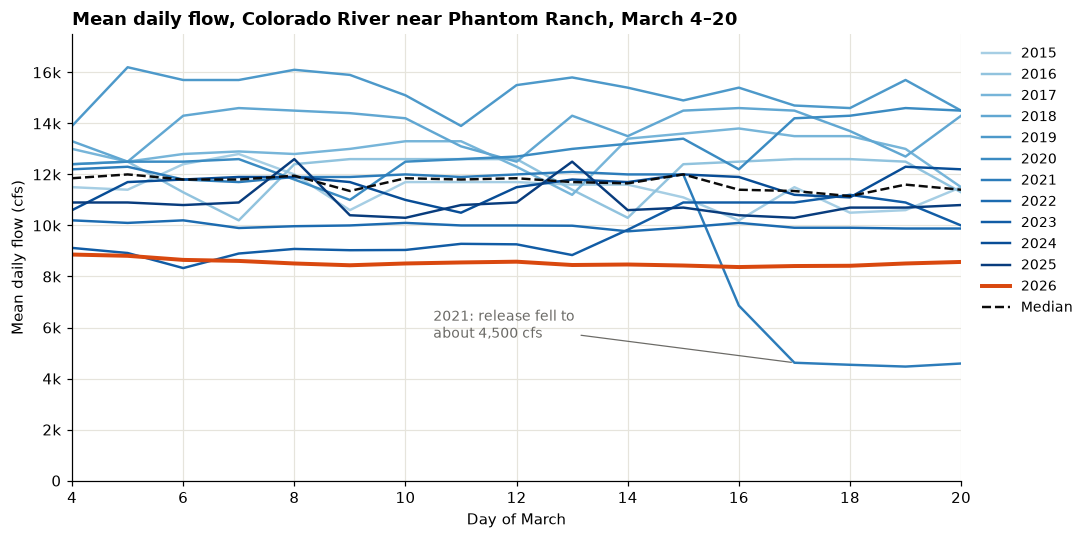

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
blues = plt.get_cmap("Blues")
earlier = [year for year in YEARS if year != YEARS[-1]]
for index, year in enumerate(earlier):
    one = days[days.year == year]
    ax.plot(
        one.day,
        one.flow_cfs,
        color=blues(0.35 + 0.6 * index / (len(earlier) - 1)),
        linewidth=1.6,
        label=str(year),
    )
latest = days[days.year == YEARS[-1]]
ax.plot(latest.day, latest.flow_cfs, color=LATEST, linewidth=2.6, label=str(YEARS[-1]))
median = days.groupby("day").flow_cfs.median()
ax.plot(
    median.index,
    median.values,
    color=INK,
    linewidth=1.6,
    linestyle="--",
    label="Median",
)

dropped = days[(days.year == 2021) & (days.flow_cfs < 6000)]
if not dropped.empty:
    first = dropped.iloc[0]
    ax.annotate(
        "2021: release fell to\nabout 4,500 cfs",
        xy=(first.day, first.flow_cfs),
        xytext=(first.day - 6.5, 5600),
        color=MUTED,
        fontsize=9,
        arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8},
    )

ax.set_title(
    "Mean daily flow, Colorado River near Phantom Ranch, March 4–20",
    loc="left",
    fontweight="bold",
)
ax.set_xlabel("Day of March")
ax.set_ylabel("Mean daily flow (cfs)")
ax.yaxis.set_major_formatter(cfs)
ax.yaxis.set_major_locator(MultipleLocator(2000))
ax.set_xlim(FIRST[1], LAST[1])
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.set_ylim(0, days.flow_cfs.max() * 1.08)
ax.legend(
    ncols=1, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9
)
fig.tight_layout()
plt.show()

Each year's range of daily flows in the window, from its lowest day to its highest, with the year's mean as a dot.

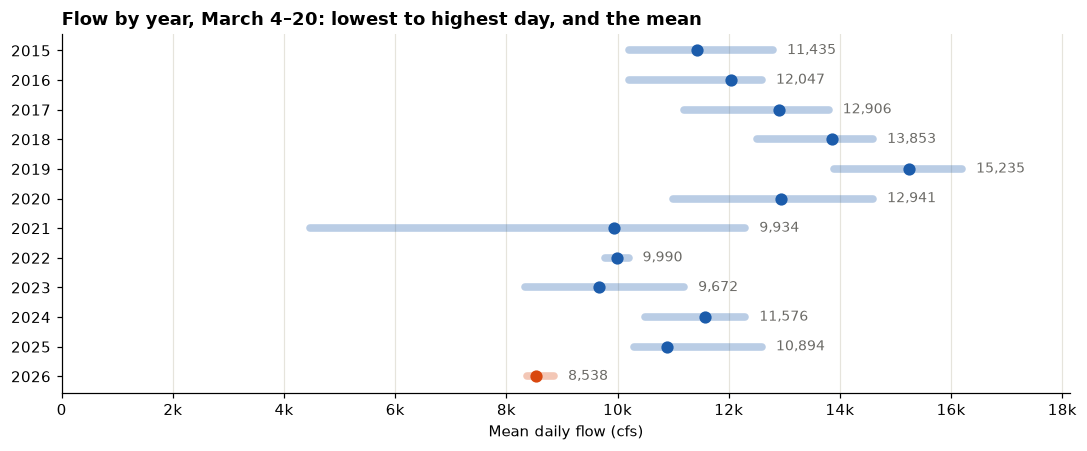

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for year, row in summary.iterrows():
    color = LATEST if year == YEARS[-1] else FLOW
    ax.plot(
        [row.lowest_flow_cfs, row.highest_flow_cfs],
        [year, year],
        color=color,
        linewidth=5,
        alpha=0.3,
        solid_capstyle="round",
    )
    ax.plot(row.mean_flow_cfs, year, "o", color=color, markersize=7)
    ax.text(
        row.highest_flow_cfs + 250,
        year,
        f"{row.mean_flow_cfs:,.0f}",
        va="center",
        fontsize=9,
        color=MUTED,
    )
ax.set_title(
    "Flow by year, March 4–20: lowest to highest day, and the mean",
    loc="left",
    fontweight="bold",
)
ax.set_xlabel("Mean daily flow (cfs)")
ax.xaxis.set_major_formatter(cfs)
ax.xaxis.set_major_locator(MultipleLocator(2000))
ax.set_xlim(0, summary.highest_flow_cfs.max() * 1.12)
ax.set_yticks(list(YEARS))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## Weather

Each day is a bar from the low to the high, in one panel per year on the same scale. The dashed line is freezing. A blue dot under a day marks precipitation, larger for more.

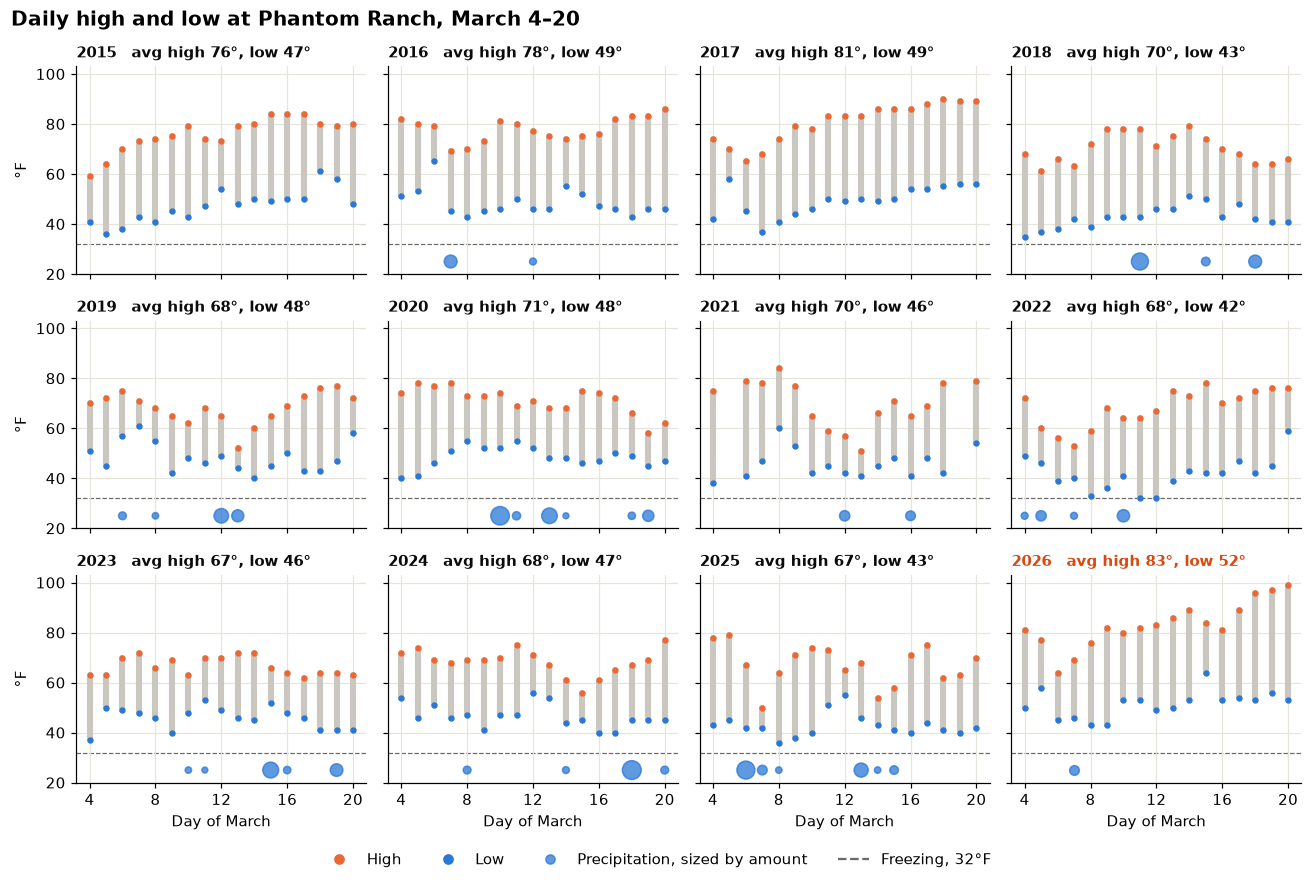

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8), sharex=True, sharey=True)
top = days.high_f.max() + 4
bottom = min(days.low_f.min(), FREEZING) - 12
largest = days.rain_in.max()
for ax, year in zip(axes.flat, YEARS, strict=True):
    one = days[days.year == year]
    for row in one.itertuples():
        if pd.notna(row.high_f) and pd.notna(row.low_f):
            ax.plot(
                [row.day, row.day],
                [row.low_f, row.high_f],
                color="#c9c7bf",
                linewidth=4,
                solid_capstyle="round",
                zorder=1,
            )
    ax.scatter(one.day, one.high_f, color=HIGH, s=10, zorder=2)
    ax.scatter(one.day, one.low_f, color=LOW, s=10, zorder=2)
    wet = one[one.rain_in >= WET]
    ax.scatter(
        wet.day,
        [bottom + 5] * len(wet),
        s=12 + 140 * wet.rain_in / largest,
        color=RAIN,
        alpha=0.75,
        zorder=2,
    )
    ax.axhline(FREEZING, color=MUTED, linewidth=0.8, linestyle="--", zorder=0)
    row = summary.loc[year]
    ax.set_title(
        f"{year}   avg high {row.mean_high_f:.0f}°, low {row.mean_low_f:.0f}°",
        loc="left",
        fontsize=10,
        fontweight="bold",
        color=LATEST if year == YEARS[-1] else INK,
    )
    ax.set_ylim(bottom, top)
    ax.set_xlim(FIRST[1] - 0.8, LAST[1] + 0.8)
    ax.xaxis.set_major_locator(MultipleLocator(4))
for ax in axes[-1]:
    ax.set_xlabel("Day of March")
for ax in axes[:, 0]:
    ax.set_ylabel("°F")
handles = [
    plt.Line2D([], [], color=HIGH, marker="o", linestyle="", label="High"),
    plt.Line2D([], [], color=LOW, marker="o", linestyle="", label="Low"),
    plt.Line2D(
        [],
        [],
        color=RAIN,
        marker="o",
        linestyle="",
        alpha=0.75,
        label="Precipitation, sized by amount",
    ),
    plt.Line2D([], [], color=MUTED, linestyle="--", label="Freezing, 32°F"),
]
fig.legend(
    handles=handles,
    ncols=4,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.01),
)
fig.suptitle(
    "Daily high and low at Phantom Ranch, March 4–20",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

What a typical day looks like across all twelve years: the median high and low on each date, with the band from the 10th to the 90th percentile. 2026 is drawn on top for comparison.

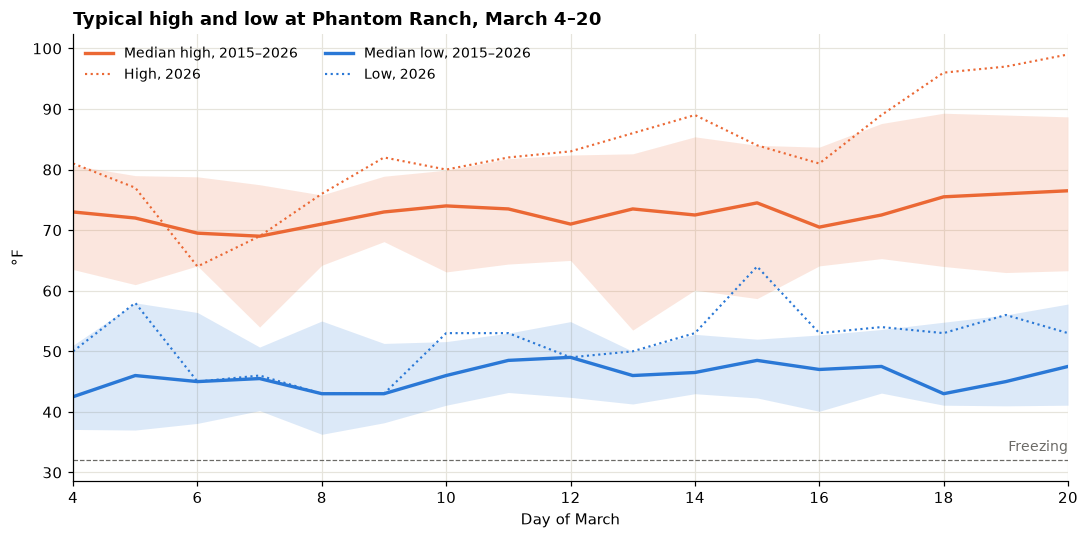

In [8]:
by_day = days.groupby("day")
fig, ax = plt.subplots(figsize=(10, 5))
for column, color, label in (("high_f", HIGH, "High"), ("low_f", LOW, "Low")):
    low_band, high_band, middle = (
        by_day[column].quantile(0.1),
        by_day[column].quantile(0.9),
        by_day[column].median(),
    )
    ax.fill_between(
        middle.index, low_band, high_band, color=color, alpha=0.16, linewidth=0
    )
    ax.plot(
        middle.index,
        middle.values,
        color=color,
        linewidth=2.2,
        label=f"Median {label.lower()}, 2015–2026",
    )
    ax.plot(
        latest.day,
        latest[column],
        color=color,
        linewidth=1.4,
        linestyle=":",
        label=f"{label}, {YEARS[-1]}",
    )
ax.axhline(FREEZING, color=MUTED, linewidth=0.8, linestyle="--")
ax.text(
    LAST[1], FREEZING + 1, "Freezing", ha="right", va="bottom", fontsize=9, color=MUTED
)
ax.set_title(
    "Typical high and low at Phantom Ranch, March 4–20", loc="left", fontweight="bold"
)
ax.set_xlabel("Day of March")
ax.set_ylabel("°F")
ax.set_xlim(FIRST[1], LAST[1])
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.legend(frameon=False, ncols=2, loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

## Rain and snow

How much precipitation fell at Phantom Ranch in each year's window, with how many days were wet, and how much snow fell on the South Rim. No snow fell at Phantom Ranch on any of these days, so the snow is the rim's. Each bar is a total over March 4–20, on its own scale.

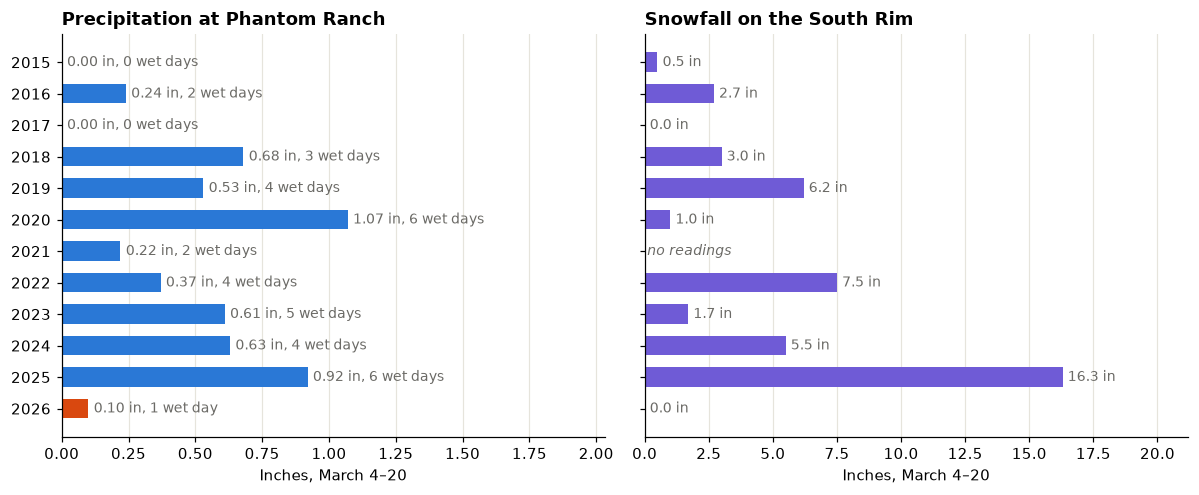

In [9]:
fig, (wet, snowy) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
order = list(YEARS)
wet.barh(
    order,
    summary.rain_in,
    color=[LATEST if year == YEARS[-1] else RAIN for year in order],
    height=0.62,
)
for year, row in summary.iterrows():
    count = int(row.rain_days)
    wet.text(
        row.rain_in + 0.02,
        year,
        f"{row.rain_in:.2f} in, {count} wet day{'s' if count != 1 else ''}",
        va="center",
        fontsize=9,
        color=MUTED,
    )
wet.set_title("Precipitation at Phantom Ranch", loc="left", fontweight="bold")
wet.set_xlabel("Inches, March 4–20")
wet.set_xlim(0, summary.rain_in.max() * 1.9)
for year, row in summary.iterrows():
    if pd.isna(row.rim_snow_in):
        snowy.text(
            0.1,
            year,
            "no readings",
            va="center",
            fontsize=9,
            color=MUTED,
            style="italic",
        )
        continue
    snowy.barh(
        year, row.rim_snow_in, color=LATEST if year == YEARS[-1] else SNOW, height=0.62
    )
    snowy.text(
        row.rim_snow_in + 0.2,
        year,
        f"{row.rim_snow_in:.1f} in",
        va="center",
        fontsize=9,
        color=MUTED,
    )
snowy.set_title("Snowfall on the South Rim", loc="left", fontweight="bold")
snowy.set_xlabel("Inches, March 4–20")
snowy.set_xlim(0, summary.rim_snow_in.max() * 1.3)
wet.set_yticks(order)
wet.invert_yaxis()
for ax in (wet, snowy):
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## Wind

Wind measured at Grand Canyon airport on the South Rim. On the left, the typical average wind on each date, with the band from the 10th to the 90th percentile across the years and 2026 on top. On the right, each year's mean wind and its strongest gust, both in mph.

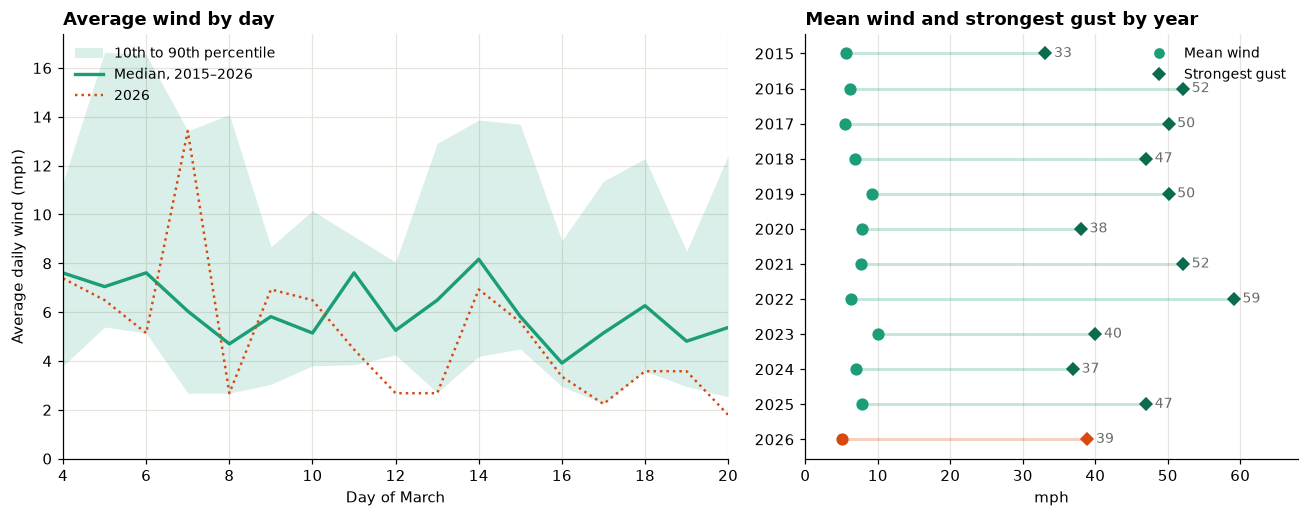

In [10]:
fig, (typical_day, by_year) = plt.subplots(
    1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.35, 1]}
)
by_date = days.groupby("day").wind_mph
band = by_date.quantile(0.1), by_date.quantile(0.9)
typical_day.fill_between(
    band[0].index,
    *band,
    color=WINDY,
    alpha=0.16,
    linewidth=0,
    label="10th to 90th percentile",
)
typical_day.plot(
    by_date.median().index,
    by_date.median().values,
    color=WINDY,
    linewidth=2.2,
    label="Median, 2015–2026",
)
typical_day.plot(
    latest.day,
    latest.wind_mph,
    color=LATEST,
    linewidth=1.6,
    linestyle=":",
    label=str(YEARS[-1]),
)
typical_day.set_title("Average wind by day", loc="left", fontweight="bold")
typical_day.set_xlabel("Day of March")
typical_day.set_ylabel("Average daily wind (mph)")
typical_day.set_xlim(FIRST[1], LAST[1])
typical_day.set_ylim(0, None)
typical_day.xaxis.set_major_locator(MultipleLocator(2))
typical_day.legend(frameon=False, fontsize=9, loc="upper left")

for year, row in summary.iterrows():
    color = LATEST if year == YEARS[-1] else WINDY
    by_year.plot(
        [row.mean_wind_mph, row.peak_gust_mph],
        [year, year],
        color=color,
        alpha=0.25,
        linewidth=2,
    )
    by_year.plot(row.mean_wind_mph, year, "o", color=color, markersize=7)
    by_year.plot(
        row.peak_gust_mph,
        year,
        "D",
        color=GUST if year != YEARS[-1] else LATEST,
        markersize=6,
    )
    by_year.text(
        row.peak_gust_mph + 1.2,
        year,
        f"{row.peak_gust_mph:.0f}",
        va="center",
        fontsize=9,
        color=MUTED,
    )
by_year.set_title("Mean wind and strongest gust by year", loc="left", fontweight="bold")
by_year.set_xlabel("mph")
by_year.set_xlim(0, summary.peak_gust_mph.max() * 1.15)
by_year.set_yticks(list(YEARS))
by_year.invert_yaxis()
by_year.grid(axis="y", visible=False)
by_year.legend(
    handles=[
        plt.Line2D([], [], color=WINDY, marker="o", linestyle="", label="Mean wind"),
        plt.Line2D(
            [], [], color=GUST, marker="D", linestyle="", label="Strongest gust"
        ),
    ],
    frameon=False,
    fontsize=9,
    loc="upper right",
)
fig.tight_layout()
plt.show()